# Проверка гипотез для увеличения выручки в интернет-магазине 

**Описание проекта**

Вы — аналитик крупного интернет-магазина. Вместе с отделом маркетинга вы подготовили список гипотез для увеличения выручки.

**Цель проекта** - приоритизировать гипотезы, запустить A/B-тест и проанализировать результаты.

**Описание данных**

Датасет `hypothesis.csv`- 9 гипотез по увеличению выручки интернет-магазина
- `Hypothesis` — краткое описание гипотезы;
- `Reach` — охват пользователей по 10-балльной шкале;
- `Impact` — влияние на пользователей по 10-балльной шкале;
- `Confidence` — уверенность в гипотезе по 10-балльной шкале;
- `Efforts` — затраты ресурсов на проверку гипотезы по 10-балльной шкале. Чем больше значение `Efforts`, тем дороже проверка гипотезы.

Датасет `orders.csv`- результаты A/B-теста
- `transactionId` — идентификатор заказа;
- `visitorId` — идентификатор пользователя, совершившего заказ;
- `date` — дата, когда был совершён заказ;
- `revenue` — выручка заказа;
- `group` — группа A/B-теста, в которую попал заказ.

Датасет `visitors.csv`-  результаты A/B-теста

- `date` — дата;
- `group` — группа A/B-теста;
- `visitors` — количество пользователей в указанную дату в указанной группе A/B-теста

**План работы**

<u>Часть 1. Приоритизация гипотез:</u>
- Применить фреймворки `ICE`и `RICE` для приоритизации гипотез
- Указать, как изменилась приоритизация гипотез при применении `RICE` вместо `ICE`

<u>Часть 2. Анализ A/B-теста:</u>
1. Построить графики:
    - кумулятивной выручки по группам,
    - кумулятивного среднего чека по группам,
    - относительного изменения кумулятивного среднего чека группы B к группе A,
    - кумулятивного среднего количества заказов на посетителя по группам,
    - относительного изменения кумулятивного среднего количества заказов на посетителя группы B к группе A;
2. Построить точечный график количества заказов по пользователям и стоимостей заказов;
3. Посчитаить 95-й и 99-й перцентили количества заказов на пользователя и стоимости заказов;
4. Посчитать статистическую значимость различий в среднем количестве заказов на посетителя между группами по «сырым» данным и по «очищенным» данным;
5. Посчитать статистическую значимость различий в среднем чеке заказа между группами по «сырым» данным и по «очищенным» данным;
6. Принять решение по результатам теста и объяснить его.

## Загрузка данных и подготовка их к анализу

In [1]:
import pandas as pd
import scipy.stats as stats
import datetime as dt
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

In [2]:
try: 
    hypothesis = pd.read_csv('/datasets/hypothesis.csv')
    orders = pd.read_csv('/datasets/orders.csv')
    visitors = pd.read_csv('/datasets/visitors.csv')
except:
    hypothesis = pd.read_csv(r'..\Downloads\hypothesis.csv')
    orders = pd.read_csv(r'..\Downloads\orders.csv')
    visitors = pd.read_csv(r'..\Downloads\visitors.csv')

### Переработка таблицы `hypothesis`

In [3]:
hypothesis.head()

,Hypothesis,Reach,Impact,Confidence,Efforts
0,"Добавить два новых канала привлечения трафика,...",3,10,8,6
1,"Запустить собственную службу доставки, что сок...",2,5,4,10
2,Добавить блоки рекомендаций товаров на сайт ин...,8,3,7,3
3,"Изменить структура категорий, что увеличит кон...",8,3,3,8
4,"Изменить цвет фона главной страницы, чтобы уве...",3,1,1,1


In [4]:
# приводим названия колонок к нижнему регистру
hypothesis.columns = hypothesis.columns.str.lower()

In [5]:
hypothesis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   hypothesis  9 non-null      object
 1   reach       9 non-null      int64 
 2   impact      9 non-null      int64 
 3   confidence  9 non-null      int64 
 4   efforts     9 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 488.0+ bytes


In [6]:
# проверяем на наличие дубликатов
hypothesis.duplicated().sum()

0

In [7]:
# проверяем кол-во пропусков
hypothesis.isna().sum()

hypothesis    0
reach         0
impact        0
confidence    0
efforts       0
dtype: int64

### Переработка таблицы `orders`

In [8]:
orders.head()

,transactionId,visitorId,date,revenue,group
0,3667963787,3312258926,2019-08-15,1650,B
1,2804400009,3642806036,2019-08-15,730,B
2,2961555356,4069496402,2019-08-15,400,A
3,3797467345,1196621759,2019-08-15,9759,B
4,2282983706,2322279887,2019-08-15,2308,B


In [9]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   transactionId  1197 non-null   int64 
 1   visitorId      1197 non-null   int64 
 2   date           1197 non-null   object
 3   revenue        1197 non-null   int64 
 4   group          1197 non-null   object
dtypes: int64(3), object(2)
memory usage: 46.9+ KB


In [10]:
# Поменяем тип столбца на datetime
orders['date'] = pd.to_datetime(orders['date'])

In [11]:
print('Минимальна дата:', orders['date'].min())
print('Максимальная дата:',orders['date'].max())

Минимальна дата: 2019-08-01 00:00:00
Максимальная дата: 2019-08-31 00:00:00


In [12]:
# проверяем на наличие дубликатов
orders.duplicated().sum()

0

In [13]:
# проверяем кол-во пропусков
orders.isna().sum()

transactionId    0
visitorId        0
date             0
revenue          0
group            0
dtype: int64

In [14]:
orders['revenue'].describe()

count    1.197000e+03
mean     8.348006e+03
std      3.919113e+04
min      5.000000e+01
25%      1.220000e+03
50%      2.978000e+03
75%      8.290000e+03
max      1.294500e+06
Name: revenue, dtype: float64

### Переработка таблицы `visitors`

In [15]:
visitors.head()

,date,group,visitors
0,2019-08-01,A,719
1,2019-08-02,A,619
2,2019-08-03,A,507
3,2019-08-04,A,717
4,2019-08-05,A,756


In [16]:
visitors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   date      62 non-null     object
 1   group     62 non-null     object
 2   visitors  62 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 1.6+ KB


In [17]:
# Поменяем тип столбца на datetime
visitors['date'] = pd.to_datetime(visitors['date'])

In [18]:
print('Минимальна дата:', visitors['date'].min())
print('Максимальная дата:',visitors['date'].max())

Минимальна дата: 2019-08-01 00:00:00
Максимальная дата: 2019-08-31 00:00:00


In [19]:
# проверяем на наличие дубликатов
visitors.duplicated().sum()

0

In [20]:
# проверяем кол-во пропусков
visitors.isna().sum()

date        0
group       0
visitors    0
dtype: int64

**Вывод**

В результате переработки 3 таблиц:

- в таблице `hypothesis` привели названия столбцов к нижнему регистру
- в таблицах `orders` и `visitors` привели тип столбца с датой к datetime
- не обнаружили пропусков и дубликатов 
- диапозон дат в таблицах `orders` и `visitors` совпадают

<div class="alert alert-warning">
    <h2> Комментарий ревьюера <a class="tocSkip"> </h2>
    
<b>Некоторые замечания и рекомендации💡:</b> 
    
Стоит проверить данные на наличие пользователей, попавших в обе группы. Пересечение групп может повлиять на результаты анализа. В реальной практике тест скорее всего пришлось бы проводить заново. В рамках нашего проекта в качестве практики можно попробовать исключить таких пользователей из заказов, при этом нужно иметь в виду, что корректно исключить их из визитов не получится, так как данные в этом датасете агрегированы.

In [21]:
orders.groupby('visitorId').agg({'group': 'nunique'}).query('group > 1').count()

group    58
dtype: int64

Кол-во пользователей, попавших в обе группы, всего 58 шт, от общего кол-ва это меньше 5%.

In [22]:
double_users = orders.groupby('visitorId').agg({'group' : 'nunique'}).reset_index().query('group > 1')['visitorId'].unique()
df = orders.query('visitorId not in @double_users')
pd.merge(df, visitors, how='inner', on=['date'])

,transactionId,visitorId,date,revenue,group_x,group_y,visitors
0,3667963787,3312258926,2019-08-15,1650,B,A,628
1,3667963787,3312258926,2019-08-15,1650,B,B,544
2,2804400009,3642806036,2019-08-15,730,B,A,628
3,2804400009,3642806036,2019-08-15,730,B,B,544
4,3797467345,1196621759,2019-08-15,9759,B,A,628
...,...,...,...,...,...,...,...
2027,2662137336,3733762160,2019-08-14,6490,B,B,746
2028,2203539145,370388673,2019-08-14,3190,A,A,735
2029,2203539145,370388673,2019-08-14,3190,A,B,746
2030,1807773912,573423106,2019-08-14,10550,A,A,735


## Часть 1. Приоритизация гипотез

Для  расчёта приоритизации гипотез используем методы `ICE` и `RICE`. Формулы для их расчета:

$$ICE = \frac{Impact * Confidence}{Efforts}$$

$$RICE = \frac{Rearch * Impact * Confidence}{Efforts}$$

Примените фреймворк `ICE` для приоритизации гипотез. Отсортируйте их по убыванию приоритета

In [23]:
hypothesis

,hypothesis,reach,impact,confidence,efforts
0,"Добавить два новых канала привлечения трафика,...",3,10,8,6
1,"Запустить собственную службу доставки, что сок...",2,5,4,10
2,Добавить блоки рекомендаций товаров на сайт ин...,8,3,7,3
3,"Изменить структура категорий, что увеличит кон...",8,3,3,8
4,"Изменить цвет фона главной страницы, чтобы уве...",3,1,1,1
5,"Добавить страницу отзывов клиентов о магазине,...",3,2,2,3
6,Показать на главной странице баннеры с актуаль...,5,3,8,3
7,Добавить форму подписки на все основные страни...,10,7,8,5
8,"Запустить акцию, дающую скидку на товар в день...",1,9,9,5


In [24]:
hypothesis['ICE'] = ((hypothesis['impact']*hypothesis['confidence'])/hypothesis['efforts']).round(2)

In [25]:
pd.set_option('display.max_colwidth', None)
hypothesis[['hypothesis','ICE']].sort_values(by='ICE', ascending=False)

,hypothesis,ICE
8,"Запустить акцию, дающую скидку на товар в день рождения",16.20
0,"Добавить два новых канала привлечения трафика, что позволит привлекать на 30% больше пользователей",13.33
7,"Добавить форму подписки на все основные страницы, чтобы собрать базу клиентов для email-рассылок",11.20
6,"Показать на главной странице баннеры с актуальными акциями и распродажами, чтобы увеличить конверсию",8.00
2,"Добавить блоки рекомендаций товаров на сайт интернет магазина, чтобы повысить конверсию и средний чек заказа",7.00
1,"Запустить собственную службу доставки, что сократит срок доставки заказов",2.00
5,"Добавить страницу отзывов клиентов о магазине, что позволит увеличить количество заказов",1.33
3,"Изменить структура категорий, что увеличит конверсию, т.к. пользователи быстрее найдут нужный товар",1.12
4,"Изменить цвет фона главной страницы, чтобы увеличить вовлеченность пользователей",1.00


Примените фреймворк `RICE` для приоритизации гипотез. Отсортируйте их по убыванию приоритета

In [26]:
hypothesis['RICE'] = (hypothesis['reach']*hypothesis['impact']*hypothesis['confidence'])/hypothesis['efforts']

In [27]:
pd.set_option('display.max_colwidth', None)
hypothesis[['hypothesis','RICE']].sort_values(by='RICE', ascending=False)

,hypothesis,RICE
7,"Добавить форму подписки на все основные страницы, чтобы собрать базу клиентов для email-рассылок",112.0
2,"Добавить блоки рекомендаций товаров на сайт интернет магазина, чтобы повысить конверсию и средний чек заказа",56.0
0,"Добавить два новых канала привлечения трафика, что позволит привлекать на 30% больше пользователей",40.0
6,"Показать на главной странице баннеры с актуальными акциями и распродажами, чтобы увеличить конверсию",40.0
8,"Запустить акцию, дающую скидку на товар в день рождения",16.2
3,"Изменить структура категорий, что увеличит конверсию, т.к. пользователи быстрее найдут нужный товар",9.0
1,"Запустить собственную службу доставки, что сократит срок доставки заказов",4.0
5,"Добавить страницу отзывов клиентов о магазине, что позволит увеличить количество заказов",4.0
4,"Изменить цвет фона главной страницы, чтобы увеличить вовлеченность пользователей",3.0


Укажите, как изменилась приоритизация гипотез при применении RICE вместо ICE. Объясните, почему так произошло

In [28]:
hypothesis[['hypothesis', 'ICE', 'RICE']].sort_values(by='RICE', ascending=False)

,hypothesis,ICE,RICE
7,"Добавить форму подписки на все основные страницы, чтобы собрать базу клиентов для email-рассылок",11.20,112.0
2,"Добавить блоки рекомендаций товаров на сайт интернет магазина, чтобы повысить конверсию и средний чек заказа",7.00,56.0
0,"Добавить два новых канала привлечения трафика, что позволит привлекать на 30% больше пользователей",13.33,40.0
6,"Показать на главной странице баннеры с актуальными акциями и распродажами, чтобы увеличить конверсию",8.00,40.0
8,"Запустить акцию, дающую скидку на товар в день рождения",16.20,16.2
3,"Изменить структура категорий, что увеличит конверсию, т.к. пользователи быстрее найдут нужный товар",1.12,9.0
1,"Запустить собственную службу доставки, что сократит срок доставки заказов",2.00,4.0
5,"Добавить страницу отзывов клиентов о магазине, что позволит увеличить количество заказов",1.33,4.0
4,"Изменить цвет фона главной страницы, чтобы увеличить вовлеченность пользователей",1.00,3.0


In [29]:
cm = sns.color_palette('flare', as_cmap=True)
hypothesis[['hypothesis', 'ICE', 'RICE']].sort_values(by='RICE', ascending=False).style.background_gradient(cmap=cm)

,hypothesis,ICE,RICE
7,"Добавить форму подписки на все основные страницы, чтобы собрать базу клиентов для email-рассылок",11.200000,112.000000
2,"Добавить блоки рекомендаций товаров на сайт интернет магазина, чтобы повысить конверсию и средний чек заказа",7.000000,56.000000
0,"Добавить два новых канала привлечения трафика, что позволит привлекать на 30% больше пользователей",13.330000,40.000000
6,"Показать на главной странице баннеры с актуальными акциями и распродажами, чтобы увеличить конверсию",8.000000,40.000000
8,"Запустить акцию, дающую скидку на товар в день рождения",16.200000,16.200000
3,"Изменить структура категорий, что увеличит конверсию, т.к. пользователи быстрее найдут нужный товар",1.120000,9.000000
1,"Запустить собственную службу доставки, что сократит срок доставки заказов",2.000000,4.000000
5,"Добавить страницу отзывов клиентов о магазине, что позволит увеличить количество заказов",1.330000,4.000000
4,"Изменить цвет фона главной страницы, чтобы увеличить вовлеченность пользователей",1.000000,3.000000


Можно отметить различие в обеих таблицах. Так, наиболее перспективные гипотезы по ICE: 8, 0, 7, по RICE: 7, 2, 0. Гипотеза 8 опустилась с первого места на пятое, при этом, разница в значениях практически не поменялась. Гипотезы 7 и 2 поднялись на 1 и 2 места соответственно из-за высокого показателя *Reach* (охват пользователей)

**Вывод**

В результате, можем предположить, что наиболее приоритетными гипотезами для увеличения выручки будут 7, 2 и 0 гипотезы

## Часть 2. Анализ A/B-теста

### 1. Постройте график кумулятивной выручки по группам

In [30]:
# создаем массив уникальных пар значений дат и групп теста
datesGroups = orders[['date','group']].drop_duplicates()

# получаем агрегированные кумулятивные по дням данные о заказах
ordersAggregated = datesGroups.apply(
    lambda x: orders[
        np.logical_and(
            orders['date'] <= x['date'], orders['group'] == x['group']
        )
    ].agg(
        {
            'date': 'max',
            'group': 'max',
            'transactionId': 'nunique',
            'visitorId': 'nunique',
            'revenue': 'sum',
        }
    ),
    axis=1,
).sort_values(by=['date', 'group'])

# получаем агрегированные кумулятивные по дням данные о посетителях интернет-магазина
visitorsAggregated = datesGroups.apply(
    lambda x: visitors[
        np.logical_and(
            visitors['date'] <= x['date'], visitors['group'] == x['group']
        )
    ].agg({'date': 'max', 'group': 'max', 'visitors': 'sum'}),
    axis=1,
).sort_values(by=['date', 'group'])

# объединяем кумулятивные данные в одной таблице и присваиваем ее столбцам понятные названия
cumulativeData = ordersAggregated.merge(
    visitorsAggregated, left_on=['date', 'group'], right_on=['date', 'group']
)
cumulativeData.columns = ['date', 'group', 'orders', 'buyers', 'revenue', 'visitors']

cumulativeData.head(5)

,date,group,orders,buyers,revenue,visitors
0,2019-08-01,A,24,20,148579,719
1,2019-08-01,B,21,20,101217,713
2,2019-08-02,A,44,38,242401,1338
3,2019-08-02,B,45,43,266748,1294
4,2019-08-03,A,68,62,354874,1845


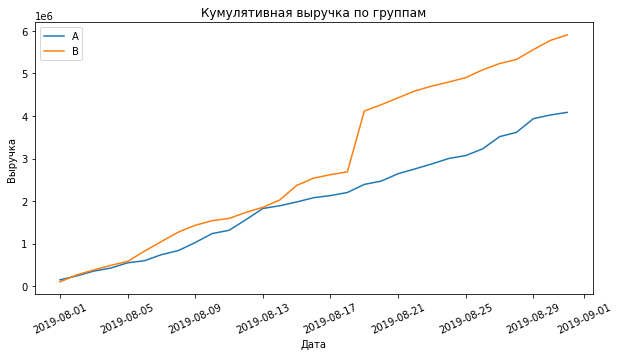

In [31]:
# датафрейм с кумулятивным количеством заказов и кумулятивной выручкой по дням в группе А
cumulativeRevenueA = cumulativeData[cumulativeData['group']=='A'][['date','revenue', 'orders']]

# датафрейм с кумулятивным количеством заказов и кумулятивной выручкой по дням в группе B
cumulativeRevenueB = cumulativeData[cumulativeData['group']=='B'][['date','revenue', 'orders']]

# строим график
plt.figure(figsize=(10,5))
plt.title('Кумулятивная выручка по группам')
plt.xlabel('Дата')
plt.ylabel('Выручка')
plt.xticks(rotation=25)
plt.plot(cumulativeRevenueA['date'], cumulativeRevenueA['revenue'], label='A')
plt.plot(cumulativeRevenueB['date'], cumulativeRevenueB['revenue'], label='B')

plt.legend()
plt.show()

Выручка почти равномерно растет в течение всего теста. Однако, выручка В группы больше чем у группы А на всем временном промежутке. Также наблюдается резкий рост выручки группы B с 17 августа. Это может сигнализировать о всплесках числа заказов, либо о появлении очень дорогих заказов в выборке. 

### 2. Постройте график кумулятивного среднего чека по группам

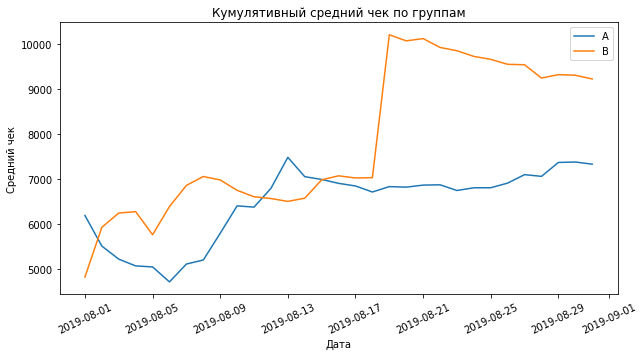

In [32]:
plt.figure(figsize=(10,5))
plt.title('Кумулятивный средний чек по группам')
plt.xlabel('Дата')
plt.ylabel('Средний чек')
plt.xticks(rotation=25)
# разделим кумулятивную выручку на кумулятивное число заказов
plt.plot(cumulativeRevenueA['date'], cumulativeRevenueA['revenue']/cumulativeRevenueA['orders'], label='A')
plt.plot(cumulativeRevenueB['date'], cumulativeRevenueB['revenue']/cumulativeRevenueB['orders'], label='B')
plt.legend()
plt.show()

График среднего чека в первой половине месяца неравномерный для обеих групп. Средний чек группы А был выше в гачале месяца, далее наблюдается спад и резкий подъем после 6 и до 13 августа, далее немного снижается и стабилизируется. В группе В наблюдается резкий и большой рост с 18 августа и далее постепенное снижение, при этом средний чек остался выше среднего чека группы А. Это также говорит нам о росте числа заказов в этой группе или о росте стоимости заказнных товаров. 

### 3. Постройте график относительного изменения кумулятивного среднего чека группы B к группе A

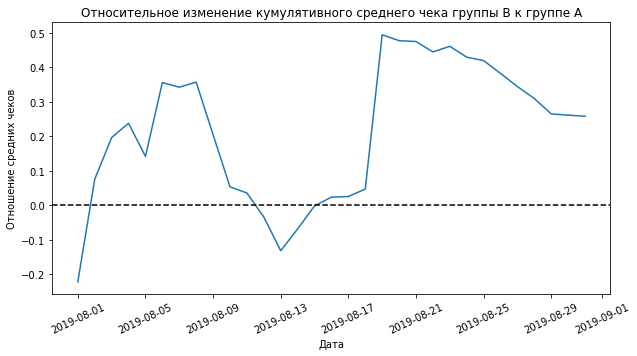

In [33]:
# собираем данные в одном датафрейме
mergedCumulativeRevenue = cumulativeRevenueA.merge(
    cumulativeRevenueB, left_on='date', right_on='date', how='left', suffixes=['A', 'B']
)

plt.figure(figsize=(10,5))
plt.title('Относительное изменение кумулятивного среднего чека группы B к группе A')
plt.xlabel('Дата')
plt.ylabel('Отношение средних чеков')
plt.xticks(rotation=25)
# cтроим отношение средних чеков
plt.plot(mergedCumulativeRevenue['date'], (mergedCumulativeRevenue['revenueB']/mergedCumulativeRevenue['ordersB'])/
         (mergedCumulativeRevenue['revenueA']/mergedCumulativeRevenue['ordersA'])-1)

# добавляем ось X
plt.axhline(y=0, color='black', linestyle='--')
plt.show()

Ожидаемо наблюдаются резкие росты и спады, график сильно «скачет», что говорит нам о наличие крупных заказов и выбросов

### 4. Постройте график кумулятивного среднего количества заказов на посетителя по группам

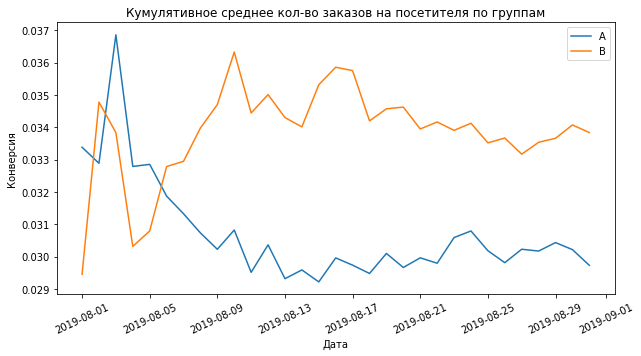

In [34]:
# считаем кумулятивную конверсию - среднее кол-во заказов на посетителя
cumulativeData['conversion'] = cumulativeData['orders']/cumulativeData['visitors']

# отделяем данные по группе A и B
cumulativeDataA = cumulativeData[cumulativeData['group']=='A']
cumulativeDataB = cumulativeData[cumulativeData['group']=='B']

# строим графики
plt.figure(figsize=(10,5))
plt.title('Кумулятивное среднее кол-во заказов на посетителя по группам')
plt.xlabel('Дата')
plt.ylabel('Конверсия')
plt.xticks(rotation=25)
plt.plot(cumulativeDataA['date'], cumulativeDataA['conversion'], label='A')
plt.plot(cumulativeDataB['date'], cumulativeDataB['conversion'], label='B')
plt.legend()
plt.show()

#plt.axis([dt.datetime(2019, 8, 1), dt.datetime(2019, 8, 31), 0, 0.05])

График несеметричный. Изначально конверсия группы А была выше группы В, далее, просев, она выросла (пик 03-08) и резко упала, стабилировавшись во второй половине месяца. Конверсия группы В была досточно низкой, далее выросла (пик 02-08) и резко просев, начала расти до стабилизации. Видно, что конверсия группы B значительно выше A после 06-08 

### 5. Постройте график относительного изменения кумулятивного среднего количества заказов на посетителя группы B к группе A

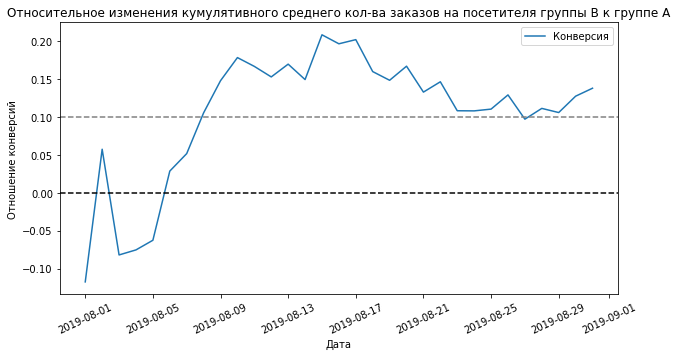

In [35]:
# объединям две таблицы
mergedCumulativeConversions = cumulativeDataA[['date','conversion']].merge(
    cumulativeDataB[['date','conversion']], 
    left_on='date', 
    right_on='date', 
    how='left', 
    suffixes=['A', 'B']
)

# строим график
plt.figure(figsize=(10,5))
plt.title('Относительное изменения кумулятивного среднего кол-ва заказов на посетителя группы B к группе A')
plt.xlabel('Дата')
plt.ylabel('Отношение конверсий')
plt.xticks(rotation=25)
plt.plot(mergedCumulativeConversions['date'], mergedCumulativeConversions['conversionB']/
         mergedCumulativeConversions['conversionA']-1,
        label='Конверсия')
plt.legend()

plt.axhline(y=0, color='black', linestyle='--')
plt.axhline(y=0.1, color='grey', linestyle='--')
plt.show()

Так как данный график напрямую зависит от предыдущих двух, общие выводы такие же. Виден рост конверсии группы В отсносительно А до 02-08, с падением 03-08 и ростом 05-08. Для корректного вывода также необходимо проанализировать аномалии

### 6. Постройте точечный график количества заказов по пользователям

In [36]:
ordersByUsers = (
    orders.groupby('visitorId', as_index=False)
    .agg({'transactionId': 'nunique'})
)

ordersByUsers.columns = ['visitorId', 'orders']
ordersByUsers.sort_values(by='orders', ascending=False).head(10)

,visitorId,orders
1023,4256040402,11
591,2458001652,11
569,2378935119,9
487,2038680547,8
44,199603092,5
744,3062433592,5
55,237748145,5
917,3803269165,5
299,1230306981,5
897,3717692402,5


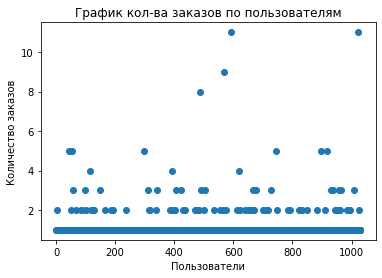

In [37]:
# строим точечную диаграмму
x_values = pd.Series(range(0,len(ordersByUsers)))

plt.scatter(x_values, ordersByUsers['orders'])
plt.title('График кол-ва заказов по пользователям')
plt.ylabel('Количество заказов')
plt.xlabel('Пользователи')
plt.show()

Больше всего пользователей, которые совершили 1 заказ. Меньше - 2 заказа. Те, кто совершил 3 заказа мало, но пока не ясно можно ли их считать выбросами. Скорее всего, пользователи, совершившие больше 5 заказов, являются аномалиями. Для точного ответа посчитаем 95 и 99 перцентили

### 7. Посчитайте 95-й и 99-й перцентили количества заказов на пользователя. Выберите границу для определения аномальных пользователей

In [38]:
np.percentile(ordersByUsers['orders'], [95, 99])

array([2., 4.])

Не более 1% пользователей сделано больше 4 заказов, и 5% пользователей сделали больше 2 заказов. Следовательно, выбираем границу для определения аномальных пользователей - 2 заказа на одного пользователя и убираем аномальных пользователей по ней

### 8. Постройте точечный график стоимостей заказов

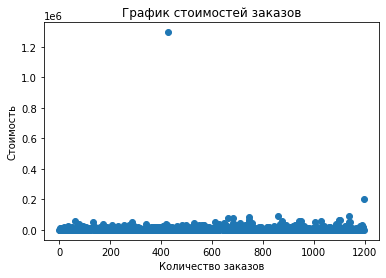

In [39]:
# строим точечную диаграмму
x_values = pd.Series(range(0,len(orders['revenue'])))

plt.scatter(x_values, orders['revenue'])
plt.title('График стоимостей заказов')
plt.ylabel('Стоимость')
plt.xlabel('Количество заказов')
plt.show()

Явно наблюдается два выброса - стоимость заказа около 1,3 млн и 200 тыс. Основная масса расположена на уровне 100 тыс. Чтобы найти более точную границу аномальных заказов рассчитаем процентили

### 9. Посчитайте 95-й и 99-й перцентили стоимости заказов. Выберите границу для определения аномальных заказов

In [40]:
np.percentile(orders['revenue'], [95, 99])

array([28000. , 58233.2])

5% пользователей сделали заказ на сумму больше 28000, и лишь 1% - на сумму больше 58233,2 у.е. Выбираем границу для определения аномальных заказов - 28000 у.е.

### 10. Посчитайте статистическую значимость различий в среднем количестве заказов на посетителя между группами по «сырым» данным

<u>Сформулируем гипотезы.</u> Нулевая: различий в среднем количестве заказов между группами нет. Альтернативная: различия в среднем между группами есть.

In [41]:
# соберем все данные по заказам, визитам и добавим кумулятивные показатели в одну таблицу
visitorsADaily = visitors[visitors['group'] == 'A'][['date', 'visitors']]
visitorsADaily.columns = ['date', 'visitorsPerDateA']

visitorsACummulative = visitorsADaily.apply(
    lambda x: visitorsADaily[visitorsADaily['date'] <= x['date']].agg(
        {'date': 'max', 'visitorsPerDateA': 'sum'}
    ),
    axis=1,
)
visitorsACummulative.columns = ['date', 'visitorsCummulativeA']

visitorsBDaily = visitors[visitors['group'] == 'B'][['date', 'visitors']]
visitorsBDaily.columns = ['date', 'visitorsPerDateB']

visitorsBCummulative = visitorsBDaily.apply(
    lambda x: visitorsBDaily[visitorsBDaily['date'] <= x['date']].agg(
        {'date': 'max', 'visitorsPerDateB': 'sum'}
    ),
    axis=1,
)
visitorsBCummulative.columns = ['date', 'visitorsCummulativeB']

ordersADaily = (
    orders[orders['group'] == 'A'][['date', 'transactionId', 'visitorId', 'revenue']]
    .groupby('date', as_index=False)
    .agg({'transactionId': pd.Series.nunique, 'revenue': 'sum'})
)
ordersADaily.columns = ['date', 'ordersPerDateA', 'revenuePerDateA']

ordersACummulative = ordersADaily.apply(
    lambda x: ordersADaily[ordersADaily['date'] <= x['date']].agg(
        {'date': 'max', 'ordersPerDateA': 'sum', 'revenuePerDateA': 'sum'}
    ),
    axis=1,
).sort_values(by=['date'])
ordersACummulative.columns = [
    'date',
    'ordersCummulativeA',
    'revenueCummulativeA',
]

ordersBDaily = (
    orders[orders['group'] == 'B'][['date', 'transactionId', 'visitorId', 'revenue']]
    .groupby('date', as_index=False)
    .agg({'transactionId': pd.Series.nunique, 'revenue': 'sum'})
)
ordersBDaily.columns = ['date', 'ordersPerDateB', 'revenuePerDateB']

ordersBCummulative = ordersBDaily.apply(
    lambda x: ordersBDaily[ordersBDaily['date'] <= x['date']].agg(
        {'date': 'max', 'ordersPerDateB': 'sum', 'revenuePerDateB': 'sum'}
    ),
    axis=1,
).sort_values(by=['date'])
ordersBCummulative.columns = [
    'date',
    'ordersCummulativeB',
    'revenueCummulativeB',
]

data = (
    ordersADaily.merge(
        ordersBDaily, left_on='date', right_on='date', how='left'
    )
    .merge(ordersACummulative, left_on='date', right_on='date', how='left')
    .merge(ordersBCummulative, left_on='date', right_on='date', how='left')
    .merge(visitorsADaily, left_on='date', right_on='date', how='left')
    .merge(visitorsBDaily, left_on='date', right_on='date', how='left')
    .merge(visitorsACummulative, left_on='date', right_on='date', how='left')
    .merge(visitorsBCummulative, left_on='date', right_on='date', how='left')
)

data.head()

,date,ordersPerDateA,revenuePerDateA,ordersPerDateB,revenuePerDateB,ordersCummulativeA,revenueCummulativeA,ordersCummulativeB,revenueCummulativeB,visitorsPerDateA,visitorsPerDateB,visitorsCummulativeA,visitorsCummulativeB
0,2019-08-01,24,148579,21,101217,24,148579,21,101217,719,713,719,713
1,2019-08-02,20,93822,24,165531,44,242401,45,266748,619,581,1338,1294
2,2019-08-03,24,112473,16,114248,68,354874,61,380996,507,509,1845,1803
3,2019-08-04,16,70825,17,108571,84,425699,78,489567,717,770,2562,2573
4,2019-08-05,25,124218,23,92428,109,549917,101,581995,756,707,3318,3280


In [42]:
# Посчитаем статистическую значимость различия в среднем количестве заказов между группами
ordersByUsersA = (
    orders[orders['group'] == 'A']
    .groupby('visitorId', as_index=False)
    .agg({'transactionId': pd.Series.nunique})
)
ordersByUsersA.columns = ['visitorId', 'orders']

ordersByUsersB = (
    orders[orders['group'] == 'B']
    .groupby('visitorId', as_index=False)
    .agg({'transactionId': pd.Series.nunique})
)
ordersByUsersB.columns = ['visitorId', 'orders']

sampleA = pd.concat(
    [
        ordersByUsersA['orders'],
        pd.Series(
            0,
            index=np.arange(
                data['visitorsPerDateA'].sum() - len(ordersByUsersA['orders'])
            ),
            name='orders',
        ),
    ],
    axis=0,
)

sampleB = pd.concat(
    [
        ordersByUsersB['orders'],
        pd.Series(
            0,
            index=np.arange(
                data['visitorsPerDateB'].sum() - len(ordersByUsersB['orders'])
            ),
            name='orders',
        ),
    ],
    axis=0,
)

alpha = 0.05

print('P-value: {0:.3f}'.format(stats.mannwhitneyu(sampleA, sampleB, alternative="two-sided")[1]))

if stats.mannwhitneyu(sampleA, sampleB, alternative="two-sided")[1] < alpha:
    print('Отвергаем нулевую гипотезу')
else: print('Не отвергаем нулевую гипотезу') 

print(
    'Относительный прирост среднего группы В к конверсии группы А: {0:.3f}'
    .format(sampleB.mean() / sampleA.mean() - 1)
)

P-value: 0.017
Отвергаем нулевую гипотезу
Относительный прирост среднего группы В к конверсии группы А: 0.138


P-value меньше 0.05, потому нулевую гипотезу отвергаем. По «сырым данным» статистически значимые различия в среднем количестве заказов между группами есть. Относительный прирост среднего группы В к конверсии группы А равен 13.8%.

### 11. Посчитайте статистическую значимость различий в среднем чеке заказа между группами по «сырым» данным

<u>Сформулируем гипотезы.</u> Нулевая: различий в среднем чеке заказа между группами нет. Альтернативная: различия в среднем между группами есть.

In [43]:
print('P-value: {0:.3f}'.format(stats.mannwhitneyu(orders[orders['group']=='A']['revenue'], orders[orders['group']=='B']['revenue'], alternative="two-sided")[1]))

if stats.mannwhitneyu(orders[orders['group']=='A']['revenue'], orders[orders['group']=='B']['revenue'], alternative="two-sided")[1] < alpha:
    print('Отвергаем нулевую гипотезу')
else: print('Не отвергаем нулевую гипотезу') 
    
print(
    'Относительное различие среднего чека между сегментами: {0:.3f}'
    .format(orders[orders['group']=='B']['revenue'].mean()/orders[orders['group']=='A']['revenue'].mean()-1)
)


P-value: 0.729
Не отвергаем нулевую гипотезу
Относительное различие среднего чека между сегментами: 0.259


P-value больше 0.05 - принимаем нулевую гипотезу. Статистически значимых отличий по «сырым данным» в среднем чеке между группами нет. При этом, относительное различие среднего чека между сегментами 25.9%

### 12. Посчитайте статистическую значимость различий в среднем количестве заказов на посетителя между группами  по «очищенным» данным

Примаем за аномальных пользователей тех, кто совершил более 3 заказов, или совершил заказ на сумму свыше 30 000 у.е. Сделаем срезы пользователей с числом заказов больше 2 — `usersWithManyOrders` и пользователей, совершивших заказы дороже 28 000 — `usersWithExpensiveOrders`. Объединим их в таблице `abnormalUsers`.

<u>Сформулируем гипотезы.</u> Нулевая: различий в среднем количестве заказов между группами нет. Альтернативная: различия в среднем между группами есть.

In [44]:
usersWithManyOrders = pd.concat(
    [
        ordersByUsersA[ordersByUsersA['orders'] > 2]['visitorId'],
        ordersByUsersB[ordersByUsersB['orders'] > 2]['visitorId'],
    ],
    axis=0,
)
usersWithExpensiveOrders = orders[orders['revenue'] > 30000]['visitorId']
abnormalUsers = (
    pd.concat([usersWithManyOrders, usersWithExpensiveOrders], axis=0)
    .drop_duplicates()
    .sort_values()
)

print(abnormalUsers.head())
print('Аномальных пользователей:', abnormalUsers.shape)

1099    148427295
18      199603092
928     204675465
23      237748145
37      249864742
Name: visitorId, dtype: int64
Аномальных пользователей: (68,)


In [45]:
# Посчитаем статистическую значимость
sampleAFiltered = pd.concat(
    [
        ordersByUsersA[
            np.logical_not(ordersByUsersA['visitorId'].isin(abnormalUsers))
        ]['orders'],
        pd.Series(
            0,
            index=np.arange(
                data['visitorsPerDateA'].sum() - len(ordersByUsersA['orders'])
            ),
            name='orders',
        ),
    ],
    axis=0,
)

sampleBFiltered = pd.concat(
    [
        ordersByUsersB[
            np.logical_not(ordersByUsersB['visitorId'].isin(abnormalUsers))
        ]['orders'],
        pd.Series(
            0,
            index=np.arange(
                data['visitorsPerDateB'].sum() - len(ordersByUsersB['orders'])
            ),
            name='orders',
        ),
    ],
    axis=0,
)

print('P-value: {0:.3f}'.format(stats.mannwhitneyu(sampleAFiltered, sampleBFiltered, alternative="two-sided")[1]))

if stats.mannwhitneyu(sampleAFiltered, sampleBFiltered, alternative="two-sided")[1] < alpha:
    print('Отвергаем нулевую гипотезу')
else: print('Не отвергаем нулевую гипотезу') 

print(
    'Относительный прирост среднего группы В к конверсии группы А: {0:.3f}'
    .format(sampleBFiltered.mean()/sampleAFiltered.mean()-1)
)

P-value: 0.013
Отвергаем нулевую гипотезу
Относительный прирост среднего группы В к конверсии группы А: 0.172


P-value меньше 0.05 - отвергаем нулевую гипотезу. По «очищенным» данным в среднем количестве заказов на посетителя между группами есть статистически значимые различия (как и в случае с сырыми данными).
Относительный прирост среднего группы В к конверсии группы А вырос до 17.2%

### Посчитайте статистическую значимость различий в среднем чеке заказа между группами по «очищенным» данным

<u>Сформулируем гипотезы.</u> Нулевая: различий в среднем чеке заказа между группами нет. Альтернативная: различия в среднем между группами есть.

In [46]:
print(
    'P-value: {0:.3f}'.format(
        stats.mannwhitneyu(
            orders[
                np.logical_and(
                    orders['group'] == 'A',
                    np.logical_not(orders['visitorId'].isin(abnormalUsers)),
                )
            ]['revenue'],
            orders[
                np.logical_and(
                    orders['group'] == 'B',
                    np.logical_not(orders['visitorId'].isin(abnormalUsers)),
                )
            ]['revenue'],alternative="two-sided"
        )[1]
    )
)

print(
    'Относительное различие среднего чека между сегментами: {0:.3f}'.format(
        orders[
            np.logical_and(
                orders['group'] == 'B',
                np.logical_not(orders['visitorId'].isin(abnormalUsers)),
            )
        ]['revenue'].mean()
        / orders[
            np.logical_and(
                orders['group'] == 'A',
                np.logical_not(orders['visitorId'].isin(abnormalUsers)),
            )
        ]['revenue'].mean()
        - 1
    )
)

P-value: 0.720
Относительное различие среднего чека между сегментами: -0.023


P-value больше 0.05 - не отвергаем нулевую гипотезу. Статистически значимых отличий в среднем чеке между группами по «очищенным» данным  нет.
Средний чек группы B стал ниже на 2% группы A (скорее всего повлиял аномальный заказ на 1.3 млн)

### 14. Примите решение по результатам теста

В результате анализа следует остановить тест и зафиксировать победу группы В. У группы B выше конверсия, чем у группы A, хотя по среднему чеку группы примерно равны.